# The latent process — one pass

1. **Distribution.** The flow map is deterministic and invertible, so $\varepsilon_\tau = \Phi^{-1}_{x_0,\tau}(x_\tau)$ is a fact about the data, not a draw. It should be $\mathcal N(0,I)$.
2. **It isn't** — spatial correlation is there, $\Sigma \neq I$.
3. **Does the mapping bias accumulate** when the map is applied repeatedly? No.
4. **Characterise $\Sigma$** — homogeneous? stationary in $t$? one scalar per frame, or a function of $t$?
5. **Whiten on the Fourier basis, fit the OU process** (Andrae §3.1–3.6): $\alpha(t,k)$, then $c(t,k)^2$.
6. **Sample from it, forecast, evaluate** — costly; configured, not run.

Prose is deliberately short. The comments in each cell carry the detail.

In [2]:
import re, sys
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from natsort import natsorted
from scipy import stats, special

sys.path.insert(0, str(Path().resolve().parent))
from Condition_model.samplers import CondSampler
from Condition_model.train import SAVE_PATH
from Condition_model.dataset import SQGLeadTimeDataset, DATA_500, DATA_PATH, NORM_STD
from Condition_model.utils import compute_rmse, compute_metrics, print_metrics, plot_metrics, visualize_results
from Condition_model.forecasting import forecast, get_latents

%matplotlib inline
# ^ AFTER the Condition_model imports: train.py calls matplotlib.use('Agg') at import
#   time and silently overrides the magic if it is issued above.

cmap   = plt.cm.viridis
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ── data ────────────────────────────────────────────────────────────────────
# One file = one WINDOW = one (trajectory, anchor) pair holding leads tau = 1..24.
# Several windows share a trajectory, so trajectory id is what any train/test
# split must be grouped on. The saved latents are ALREADY in normalised model
# units (the dataset divided by NORM_STD before the inversion) — never divide again.
PRIMARY = DATA_PATH / 'invert_steps=1000'   # N=64,  1000 Euler steps — highest fidelity
ROBUST  = DATA_PATH / 'invert_steps=100'    # N=387,  100 Euler steps

def load_invert(dir_):
    """Load every inverted-latent file in one directory.

    Args:
        dir_ : directory of invert_traj{T}initial{A}.npy files. Each file is ONE window
               = one (trajectory T, anchor A) pair holding leads tau = 1..24.

    Returns:
        Z     : (N, L, C, H, W) float32 — latents, already in normalised model units
        traj  : (N,) int — trajectory id per window; LOCAL to the val split (files[400:]),
                so index ds.data with it, never a full 500-file dataset
        anch  : (N,) int — anchor frame per window; lead k pairs with frame anch + 1 + k
        files : list of Path — kept so §3 can re-open the same windows
    """
    files = natsorted(Path(dir_).glob('invert_traj*initial*.npy'))
    Z     = np.stack([np.load(f).astype(np.float32) for f in files])
    meta  = np.array([[int(m.group(1)), int(m.group(2))] for f in files
                      for m in [re.search(r'invert_traj(\d+)initial(\d+)', f.name)]])
    return Z, meta[:, 0], meta[:, 1], files        # Z, traj id, anchor frame, paths

Z, traj, anch, files = load_invert(PRIMARY)
N, L, C, H, W = Z.shape
d = C * H * W                                      # 8192 real dof per field
leads = np.arange(1, L + 1)                        # Z[:, j] is lead tau = j+1 h

# ── Fourier-ring machinery ──────────────────────────────────────────────────
# Sigma of a spatially stationary field on a periodic grid is diagonalised by the
# 2-D Fourier basis; isotropy ties the eigenvalue to |k|, so an integer radial ring
# is one near-degenerate eigen-block. Rings are the whitening basis used from §5 on.
ky, kx = np.meshgrid(np.fft.fftfreq(H) * H, np.fft.fftfreq(W) * W, indexing='ij')
kr     = np.round(np.sqrt(kx ** 2 + ky ** 2)).astype(int)     # ring index per mode
B      = kr.max() + 1                                         # 46 rings: 0 = DC .. 45 = corners
K_ISO  = H // 2                                               # rings 1..32 = isotropic range
ring_n = np.bincount(kr.ravel(), minlength=B)                 # modes per ring, one channel
dof_b  = ring_n * C                                           # REAL dof per ring per window
assert dof_b.sum() == d                                       # Parseval: the rings exhaust the field

# one-hot ring indicator; a (B, H*W) matmul is 'sum over the modes of each ring'
RING = np.zeros((B, H * W), np.float32)
RING[kr.ravel(), np.arange(H * W)] = 1.0

GROUPS = [(1, 2), (3, 4), (5, 8), (9, 16), (17, 32)]          # readable bands; fits stay per-ring
gcol   = {g: cmap(x) for g, x in zip(GROUPS, np.linspace(0.02, 0.82, len(GROUPS)))}

def ring_bin(P2d):
    """Average a per-mode quantity into radial rings.

    Args:
        P2d : (..., H, W) — anything defined per Fourier mode (power, cross-spectrum,
              eigenvector weight). Leading axes are untouched.

    Returns:
        (..., B) — the MEAN over the modes of each ring. Mean, not sum: ring_n varies by
        two orders of magnitude across rings, so a sum would confound size with power.
    """
    flat = P2d.reshape(-1, H * W)
    return ((flat @ RING.T) / ring_n).reshape(*P2d.shape[:-2], B)

def periodogram(Zin):
    """Per-mode power |z_hat(k)|^2 of every field.

    Args:
        Zin : (n, L, C, H, W) fields in model units

    Returns:
        (n, L, C, H, W) float32 — power per mode / channel / lead / window. NOT divided
        by H*W; divide by it for eigenvalue units. Uncentred, i.e. the raw second
        moment, which is what H0 is stated about.
    """
    return (np.abs(np.fft.fft2(Zin, axes=(-2, -1))) ** 2).astype(np.float32)

def traj_split(traj_ids, frac=0.7, seed=0):
    """Train/test split grouped by TRAJECTORY, not by window.

    A window-level split would leak: windows from one trajectory can overlap in time
    (anchor gap < 24 h) and then hold literally the same frames on both sides.

    Args:
        traj_ids : (N,) trajectory id per window
        frac     : target share of WINDOWS on the train side. Approximate — whole
                   trajectories are indivisible, so the realised split overshoots a little.
        seed     : RNG seed for the trajectory shuffle; vary it to repeat the split.

    Returns:
        (train_idx, test_idx) — two int arrays of window indices, disjoint in trajectory.
    """
    u = np.unique(traj_ids); np.random.default_rng(seed).shuffle(u)
    keep, n = [], 0
    for t in u:
        if n < frac * len(traj_ids):
            keep.append(t); n += (traj_ids == t).sum()
    m = np.isin(traj_ids, keep)
    return np.where(m)[0], np.where(~m)[0]

def traj_boot(traj_ids, stat, n_boot=200, seed=0):
    """Bootstrap error bars by resampling whole TRAJECTORIES with replacement.

    Leads inside a window are strongly correlated (that is the entire alpha story) and
    windows can share a trajectory, so chi^2 or iid error bars are invalid here. The
    trajectory is the only independent replicate, which is what this resamples.

    Args:
        traj_ids : (N,) trajectory id per window
        stat     : callable. Receives the resampled window INDICES (int array, with
                   repeats) and returns an array of fixed shape. Taking indices rather
                   than data keeps it usable for PAIRED statistics across two arrays.
        n_boot   : number of resamples. 200 suffices for an sd, not for a 1% tail.
        seed     : RNG seed.

    Returns:
        (n_boot, *stat_shape) — stacked statistic. .std(0) for an error bar,
        np.percentile(..., [2.5, 97.5], axis=0) for a CI.
    """
    rng, u = np.random.default_rng(seed), np.unique(traj_ids)
    return np.stack([stat(np.concatenate([np.where(traj_ids == t)[0]
                                          for t in rng.choice(u, len(u), replace=True)]))
                     for _ in range(n_boot)])

print(f"Z {Z.shape}: {N} windows from {len(np.unique(traj))} trajectories, leads 1..{L} h")
print(f"rings: {B} total, isotropic 1..{K_ISO};  device = {device}")

Z (64, 24, 2, 64, 64): 64 windows from 48 trajectories, leads 1..24 h
rings: 46 total, isotropic 1..32;  device = cuda


## 1. Distribution of $\varepsilon$

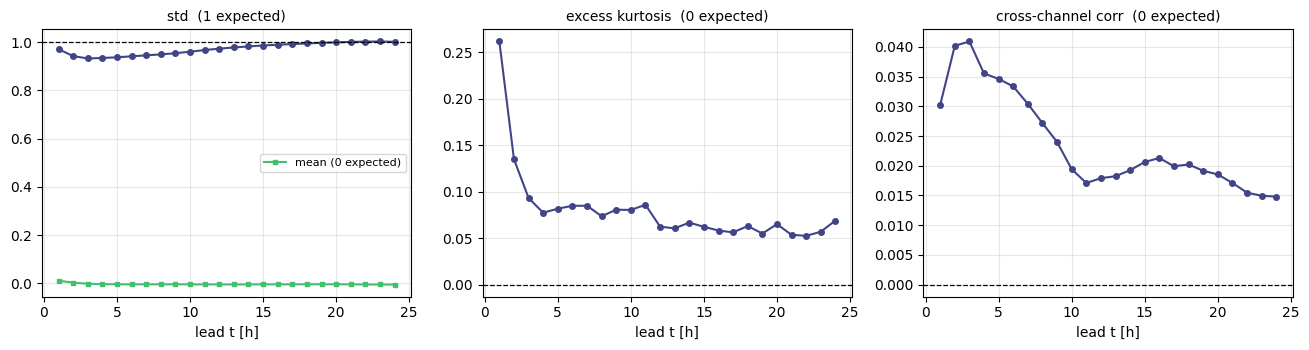

pooled over all leads:  mean -0.0037   std 0.9726   excess kurtosis +0.0865
per-lead std   range [0.9323, 1.0028]
per-lead kurt  range [+0.0525, +0.2618]
cross-channel  range [+0.0148, +0.0409]


In [3]:
# Pool each lead over windows, channels and pixels -> one marginal per lead.
Zl = Z.transpose(1, 0, 2, 3, 4).reshape(L, -1)        # (L, N*C*H*W)

mean_l = Zl.mean(1)
std_l  = Zl.std(1)
kurt_l = stats.kurtosis(Zl, axis=1)                   # EXCESS kurtosis: 0 for Gaussian

# cross-channel correlation per lead: N(0, I) => the two SQG levels are independent
c0, c1 = Z[:, :, 0].reshape(N, L, -1), Z[:, :, 1].reshape(N, L, -1)
xchan  = np.array([np.corrcoef(c0[:, t].ravel(), c1[:, t].ravel())[0, 1] for t in range(L)])

fig, axes = plt.subplots(1, 3, figsize=(13.2, 3.6))
for ax, y, ttl, ref in [(axes[0], std_l,  'std  (1 expected)',              1.0),
                        (axes[1], kurt_l, 'excess kurtosis  (0 expected)',  0.0),
                        (axes[2], xchan,  'cross-channel corr  (0 expected)', 0.0)]:
    ax.plot(leads, y, 'o-', ms=4, color=cmap(0.2)); ax.axhline(ref, color='k', lw=0.9, ls='--')
    ax.set_xlabel('lead t [h]'); ax.set_title(ttl, fontsize=10); ax.grid(alpha=0.3)
axes[0].plot(leads, mean_l, 's-', ms=3, color=cmap(0.7), label='mean (0 expected)'); axes[0].legend(fontsize=8)
fig.tight_layout(); plt.show()

print(f"pooled over all leads:  mean {Z.mean():+.4f}   std {Z.std():.4f}   "
      f"excess kurtosis {stats.kurtosis(Z.ravel()):+.4f}")
print(f"per-lead std   range [{std_l.min():.4f}, {std_l.max():.4f}]")
print(f"per-lead kurt  range [{kurt_l.min():+.4f}, {kurt_l.max():+.4f}]")
print(f"cross-channel  range [{xchan.min():+.4f}, {xchan.max():+.4f}]")

## 2. But the pixels are not independent

Per-pixel marginals say nothing about $\Sigma$. The ring spectrum does: under $\Sigma = I$ the per-mode density $\lambda(k)/\mathrm{Var}$ is **flat at 1**.

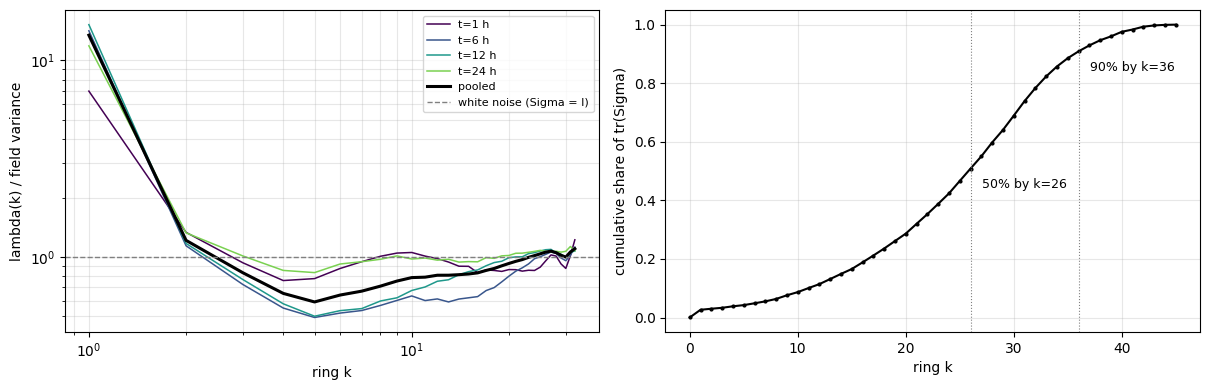

lambda(k)/var:  k=1 13.45   k=5 0.59   k=16 0.83   k=32 1.10    (all 1.00 if Sigma = I)
tr(Sigma) share:  k<=2 3.0%   k<=8 6.3%

across leads: total energy varies x1.16, but per-ring max/min spans x1.06 .. x2.20
=> the rings move by DIFFERENT factors, so Sigma_t is not one Sigma scaled by a
   scalar sigma(t)^2 — the SHAPE changes with lead, not just the level.


In [4]:
# lambda(k) = E|z_hat(k)|^2 / (H*W), in eigenvalue units, normalised by the field variance.
P        = periodogram(Z)                                   # (N, L, C, H, W)
lam      = ring_bin(P.mean(axis=(0, 1))).mean(0) / (H * W)  # pooled over windows, leads, channels
lam_lead = np.stack([ring_bin(P[:, t].mean(0)).mean(0) / (H * W) for t in range(L)])
var_f    = Z.var()

# ring share of tr(Sigma): weight each ring by its REAL dof, not by 1
share = lam * dof_b / (lam * dof_b).sum()
ks    = np.arange(1, K_ISO + 1)

fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.0))
for i, t in enumerate([1, 6, 12, 24]):
    axes[0].loglog(ks, lam_lead[t-1, 1:K_ISO+1] / var_f, '-', lw=1.1, color=cmap(0.8*i/3), label=f't={t} h')
axes[0].loglog(ks, lam[1:K_ISO+1] / var_f, 'k-', lw=2.2, label='pooled')
axes[0].axhline(1.0, color='gray', lw=1.0, ls='--', label='white noise (Sigma = I)')
axes[0].set_xlabel('ring k'); axes[0].set_ylabel('lambda(k) / field variance')
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3, which='both')

axes[1].plot(np.arange(B), np.cumsum(share), 'k.-', ms=4)
for q in (0.5, 0.9):
    kq = int(np.searchsorted(np.cumsum(share), q))
    axes[1].axvline(kq, color='gray', lw=0.8, ls=':')
    axes[1].annotate(f'{q:.0%} by k={kq}', (kq, q), textcoords='offset points', xytext=(8, -12), fontsize=9)
axes[1].set_xlabel('ring k'); axes[1].set_ylabel('cumulative share of tr(Sigma)'); axes[1].grid(alpha=0.3)
fig.tight_layout(); plt.show()

print(f"lambda(k)/var:  k=1 {lam[1]/var_f:.2f}   k=5 {lam[5]/var_f:.2f}   "
      f"k=16 {lam[16]/var_f:.2f}   k=32 {lam[32]/var_f:.2f}    (all 1.00 if Sigma = I)")
print(f"tr(Sigma) share:  k<=2 {np.cumsum(share)[2]:.1%}   k<=8 {np.cumsum(share)[8]:.1%}")

# Same ring, different leads: the coloured curves above do NOT lie on top of each other.
# If Sigma_t were one fixed Sigma times a scalar sigma(t)^2, every ring would move by the
# SAME factor between two leads. Compare the total-energy factor with the per-ring spread:
E_lead = (lam_lead * dof_b[None, :]).sum(1)                       # total latent energy per lead
spread = lam_lead[:, 1:K_ISO+1].max(0) / lam_lead[:, 1:K_ISO+1].min(0)   # per-ring max/min over t
print(f"\nacross leads: total energy varies x{E_lead.max()/E_lead.min():.2f}, "
      f"but per-ring max/min spans x{spread.min():.2f} .. x{spread.max():.2f}")
print(f"=> the rings move by DIFFERENT factors, so Sigma_t is not one Sigma scaled by a")
print(f"   scalar sigma(t)^2 — the SHAPE changes with lead, not just the level.")

### 2b. Is $\Sigma$ an artifact of the inversion?

Pooled ring spectrum from each inversion. If $\Sigma \neq I$ came from the integrator, the curves would separate.

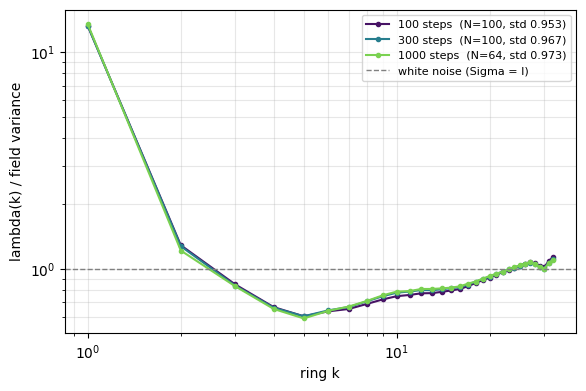

In [5]:
# Pooled, NOT paired: the three sets hold different windows (300 and 1000 share all 64,
# but 100 overlaps them by only 4), so this compares the pooled Sigma of each inversion
# rather than matched pairs. Enough to see whether step count moves the spectrum at all.
fig, ax = plt.subplots(figsize=(6.6, 4.2))
for i, (n_steps, dir_) in enumerate([(100, ROBUST),
                                     (300, DATA_PATH / 'invert_steps=300'),
                                     (1000, PRIMARY)]):
    Zs    = load_invert(dir_)[0]
    lam_s = ring_bin(periodogram(Zs).mean(axis=(0, 1))).mean(0) / (H * W)     # (B,)
    ax.loglog(ks, lam_s[1:K_ISO+1] / Zs.var(), 'o-', ms=3, lw=1.5, color=cmap(0.05 + 0.75*i/2),
              label=f'{n_steps} steps  (N={len(Zs)}, std {Zs.std():.3f})')
ax.axhline(1.0, color='gray', lw=1.0, ls='--', label='white noise (Sigma = I)')
ax.set_xlabel('ring k'); ax.set_ylabel('lambda(k) / field variance')
ax.legend(fontsize=8); ax.grid(alpha=0.3, which='both'); plt.show()

## 3. Does the bias of the mapping accumulate?

$\Sigma \neq I$ means the inversion dumps model error into $\varepsilon$. Push the latents back through the forward ODE: each lead is its own map $\Phi_{x_0,\tau}$ from the **same** anchor, nothing is chained, so the question is whether the round-trip error grows with $\tau$.

CRPS needs an ensemble and the round trip has exactly one member. So the yardstick is a separate **ens = 20** forecast: the bias only matters if it is comparable to the forecast error it would sit inside.

In [3]:
# The anchor each file was inverted against. traj_idx is LOCAL to the val split
# (files[400:]); resolving it against the full 500-file dir reads a trajectory 400 too early.
ds     = SQGLeadTimeDataset(DATA_500, split='val', random_lead_time=False, eval_traj_num=100, seed=42)
labels = torch.tensor([k / L for k in range(1, L + 1)], dtype=torch.float32)

def roundtrip(paths, steps, save_dir):
    '''Push saved latents back through the forward ODE and pair them with the truth.

    Args:
        paths : list of Path to invert_traj{T}initial{A}.npy files.
        steps : Euler steps for the FORWARD integration. MUST match the directory the
                latents came from (invert_steps=1000/ -> 1000). A mismatch produces
                error that grows with lead and would be read as the answer.

    Returns:
        (pred, truth) : both (n_files, L, C, H, W) float32, in PHYSICAL units.
        ds.data was divided by NORM_STD at load, so both are multiplied back by it, and
        the scores then land on the same scale as the observed fields.
    '''
    save_dir.mkdir(parents=True, exist_ok=True)  
    smp = CondSampler(model_path=SAVE_PATH, device=device, steps=steps)
    Pr, Tr = [], []
    for f in paths:
        tj, a = map(int, re.search(r'invert_traj(\d+)initial(\d+)', f.name).groups())
        eps   = torch.from_numpy(np.load(f).astype(np.float32))          # (L, C, H, W)
        pred  = smp.sample(z0=eps, x_t=ds.data[tj][a].expand(L, -1, -1, -1), lead_times=labels)
        truth = ds.data[tj][a + 1: a + 1 + L]                            # leads 1..L, NOT a:a+L
        Pr.append(pred.numpy())
        Tr.append(truth.numpy())
        # save the round trip physical window
        fname = f"traj{tj}initial{a}.npy"
        np.save(save_dir / fname, np.stack([pred, truth], axis=0))
    return NORM_STD * np.stack(Pr), NORM_STD * np.stack(Tr)

# ---- (a) the mapping's own bias: round trip at EVERY available step count ----
# Paired on purpose: only windows present in all three directories are used, so the arms
# share trajectories, anchors and truth, and the ONLY difference is the integrator.
STEP_DIRS = {100: ROBUST, 300: DATA_PATH / 'invert_steps=300', 1000: PRIMARY}
shared = sorted(set.intersection(*[{f.name for f in d.glob('invert_traj*initial*.npy')}
                                   for d in STEP_DIRS.values()]))
assert shared, 'no window is present in every step-count directory'

N_RT = 10        # runtime is dominated by steps=1000 (~2.5 min/window; ~45 s at 300,
                 # ~15 s at 100), so all three arms at N_RT=10 is roughly 35 min.
use  = shared[:N_RT]
print(f'{len(shared)} windows shared by all step counts; using {len(use)}')

RT = {}          # step count -> (N_RT, L) RMSE per window per lead, PHYSICAL units
for s, d in STEP_DIRS.items():
    P, T   = roundtrip([d / n for n in use], steps=s,
                       save_dir=DATA_PATH / 'round_trip' / f'steps={s}')
    RT[s]  = np.stack([compute_rmse(p, t) for p, t in zip(P, T)])
    sd_field = T.std()        # identical across arms — same windows, same truth
    print(f'  steps={s:>4}:  RMSE t=1 {RT[s][:, 0].mean():7.2f}   t=24 {RT[s][:, 23].mean():7.2f}')
print(f'field std {sd_field:.1f} (physical units)')

64 windows shared by all step counts; using 10


KeyboardInterrupt: 

In [ ]:
# Round-trip RMSE at every step count, against a real forecast, on ONE axis, 0-24 h.
#
# UNITS — the whole point. RT is PHYSICAL (roundtrip multiplies by NORM_STD);
# compute_metrics works on ds.data, already divided by NORM_STD, so forecast RMSE is
# NORMALISED. Dividing RT by NORM_STD puts both on one axis; comparing 3.5 against 0.3
# without it is a factor-2660 error.
#
# Forecast side reuses what perform_forecasting already wrote to disk — no GPU here.
# Truncated to the first window: past lead 24 the AR loop re-anchors on its own forecast,
# which is not what the model was trained on.
fc_dir = DATA_PATH / 'predit_alpha=0.5'
fc     = [(torch.from_numpy(np.load(fc_dir / f'sample{i:02d}_predicts.npy')),
           torch.from_numpy(np.load(fc_dir / f'sample{i:02d}_truth.npy')))
          for i in range(len(list(fc_dir.glob('*_predicts.npy'))))]
m_fc   = compute_metrics(fc)

fig, ax = plt.subplots(figsize=(7.4, 4.6))
steps_sorted = sorted(RT)
for i, s in enumerate(steps_sorted):
    ax.plot(leads, RT[s].mean(0) / NORM_STD, 'o-', ms=4, lw=1.8,
            color=cmap(0.05 + 0.7 * i / max(len(steps_sorted) - 1, 1)),
            label=f'round trip, {s} steps')
ax.plot(m_fc['lead_times'][:L], m_fc['rmse'][:L], '-', lw=2.4, color='k',
        label=f"forecast, ens=20 alpha=0.5 ({len(fc)} samples)")
ax.set_yscale('log')              # round trip and forecast are ~100x apart
ax.set_xlim(0, 24)
ax.set_xlabel('lead time [h]'); ax.set_ylabel('RMSE  [normalised units]')
ax.set_title('round-trip error vs forecast error, first 24 h', fontsize=10)
ax.legend(fontsize=8); ax.grid(alpha=0.3, which='both')
fig.tight_layout(); plt.show()

print(f"{'steps':>7}{'RMSE t=1':>12}{'RMSE t=24':>12}{'growth 24/2':>14}{'% of forecast t=24':>21}")
for s in steps_sorted:
    r = RT[s].mean(0) / NORM_STD
    print(f'{s:>7}{r[0]:>12.6f}{r[23]:>12.6f}{(RT[s][:, 23] / RT[s][:, 1]).mean():>13.2f}x'
          f'{r[23] / m_fc["rmse"][23]:>20.2%}')
print(f'{"forecast":>7}{m_fc["rmse"][0]:>12.6f}{m_fc["rmse"][23]:>12.6f}')
print(f'\nx10 steps (100 -> 1000): RMSE falls x{RT[100].mean() / RT[1000].mean():.1f}'
      f'   => first-order Euler, a DISCRETISATION floor, not error feeding back')

## 4. Does the Fourier basis diagonalise $\Sigma$?

§2 already settled that $\Sigma_t$ moves with lead and is not one $\Sigma$ times a scalar. What is left to check is the **basis**: rings are only the right coordinates if distinct Fourier modes are uncorrelated.

$$\gamma_t(k,k') = \frac{\big|\tfrac1N\sum_n \hat z_t(k)\,\hat z_t(k')^*\big|}{\sqrt{\hat S_t(k)\,\hat S_t(k')}},\qquad k' \neq \pm k$$

$|\gamma|$ is the magnitude of a complex average, so under the null it floors **above** zero — at $\tfrac{\sqrt\pi}{2\sqrt{N_{\rm eff}}}$ with $N_{\rm eff}$ the number of independent **trajectories**. Comparing against 0 would manufacture a finding.

null E|gamma| = 0.1279   (N_eff = 48 trajectories)
  t= 1 h   mean 0.1156   p95 0.2237   max 0.4474
  t= 4 h   mean 0.1145   p95 0.2220   max 0.3974
  t=12 h   mean 0.1131   p95 0.2213   max 0.3638
  t=24 h   mean 0.1135   p95 0.2200   max 0.3638


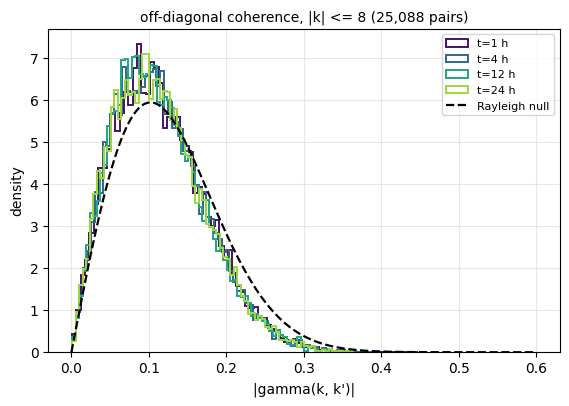

In [13]:
# Conjugate pairs are identically coherent for a real field (z(-k) = conj(z(k))) and must
# be excluded, or the test reports a tautology. Channel 0 only; channels are pooled
# everywhere else in this notebook and cross-channel structure is deliberately out of scope.
sel    = np.where(kr.ravel() <= 8)[0]
ii, jj = np.unravel_index(sel, (H, W))
conj   = ((-ii) % H) * W + ((-jj) % W)
off    = ~np.eye(len(sel), dtype=bool) & ~(sel[None, :] == conj[:, None])
zh     = np.fft.fft2(Z, axes=(-2, -1)).reshape(N, L, C, H * W)[:, :, 0, :][:, :, sel]

Neff = len(np.unique(traj))
fig, ax = plt.subplots(figsize=(6.6, 4.2))
print(f"null E|gamma| = {np.sqrt(np.pi)/2/np.sqrt(Neff):.4f}   (N_eff = {Neff} trajectories)")
for i, t in enumerate([1, 4, 12, 24]):
    x  = zh[:, t-1, :]
    Cm = (x.conj().T @ x) / N                      # per-mode cross-spectral matrix
    dg = np.sqrt(np.abs(np.diag(Cm)))
    G  = (np.abs(Cm) / np.outer(dg, dg))[off]
    ax.hist(G, bins=80, density=True, histtype='step', lw=1.4, color=cmap(0.05+0.8*i/3), label=f't={t} h')
    print(f"  t={t:>2} h   mean {G.mean():.4f}   p95 {np.percentile(G,95):.4f}   max {G.max():.4f}")
gg = np.linspace(0, 0.6, 300)
ax.plot(gg, 2*Neff*gg*np.exp(-Neff*gg**2), 'k--', lw=1.6, label='Rayleigh null')
ax.set_xlabel("|gamma(k, k')|"); ax.set_ylabel('density')
ax.set_title(f'off-diagonal coherence, |k| <= 8 ({off.sum()//2:,} pairs)', fontsize=10)
ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.show()

## 5. Whiten on the Fourier basis, then fit the process

Andrae §3.4–3.6. Per whitened coordinate $i$ the marginal-preserving SDE $d\varepsilon^{(i)} = -\tfrac12 c_i^2\varepsilon^{(i)}dt + c_i\,dW$ has closed form

$$\varepsilon^{(i)}_t = \alpha_i(t)\,\varepsilon^{(i)}_0 + \sqrt{1-\alpha_i(t)^2}\;\eta_i,\qquad
\alpha_i(t)=\exp\!\Big(-\tfrac12\!\int_0^t\! c_i(u)^2du\Big),\qquad
c_i(t)^2 = -2\,\tfrac{d}{dt}\log\alpha_i(t)$$

and $\mathbb E[\varepsilon_t\mid\varepsilon_0] = \alpha(t)\varepsilon_0$, so $\hat\alpha$ is the minimiser of $\mathcal L=\mathbb E\|\varepsilon_t-\alpha\varepsilon_0\|^2$ — plain least squares.

"Coordinates evolve independently" holds in the **whitened Fourier** basis, not in pixels (§4 says the basis is right; §2 says the whitening must be per-lead, $S_t(k)$, not one $S(k)$). $i \to$ ring $k$. $\varepsilon_0 := \varepsilon_{\tau=1}$; there is no $\tau=0$ latent.

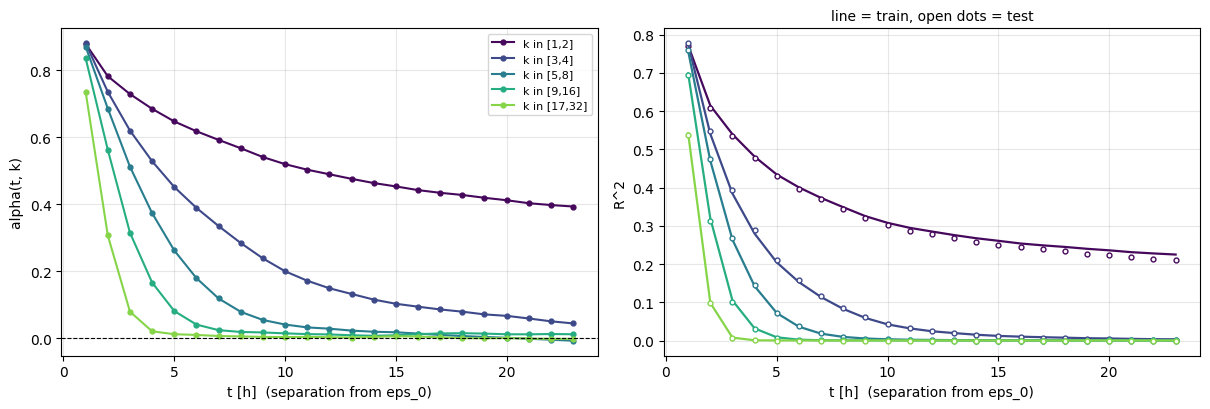

train/test gap over all (t,k): mean +0.0008   worst cell 0.0162   => alpha(t,k) generalises to unseen trajectories
   (single-split worst cell 0.217 — small rings hold only 8-12 modes, so one split is noisy; the average is the signal)
 t [h]    R2 mean over rings    R2 scalar alpha(t)
     1              0.6343                0.6260   x1.0
     2              0.2582                0.2040   x1.3
     4              0.0737                0.0174   x4.2
     8              0.0281                0.0020   x14.3
    16              0.0157                0.0006   x28.1


In [9]:
def ring_moments(Zin, mu):
    """Ring-summed auto- and cross-moments — everything the per-ring least squares needs.

    No 8192x8192 covariance is ever formed. Chunked over windows so the complex FFT
    never materialises for the whole set at once.

    Args:
        Zin : (n, L, C, H, W) latents
        mu  : mean field to subtract, broadcastable to Zin. Pass the TRAIN mean only —
              the full-set mean would leak test information into the fit.

    Returns:
        S : (n, L, B) — sum over the modes of ring b and over channels of |z_hat_l(k)|^2.
        X : (n, L, B) — same sum of Re[z_hat_l(k) conj(z_hat_0(k))], the cross-moment of
            lead l with lead 0. X[:, 0, :] == S[:, 0, :] by construction.

    SUMS, not means (unlike ring_bin): these accumulate across windows before any
    division, so the ratio forming alpha is a pooled least-squares solution.
    """
    n = Zin.shape[0]
    S, X = np.empty((n, L, B)), np.empty((n, L, B))
    for i in range(0, n, 32):
        zh = np.fft.fft2(Zin[i:i+32] - mu, axes=(-2, -1))
        p  = (zh.real**2 + zh.imag**2).reshape(-1, C, H*W).sum(1)
        c  = (zh * np.conj(zh[:, :1])).real.reshape(-1, C, H*W).sum(1)
        S[i:i+32] = (p @ RING.T).reshape(-1, L, B)
        X[i:i+32] = (c @ RING.T).reshape(-1, L, B)
    return S, X

def fit_alpha(Zin, tr, te):
    """Whiten on TRAIN statistics, fit alpha(t,k) on TRAIN, score both splits.

    Whitening is per (lead, ring): v(t,k) = E_train[S_tt(k)] / (H*W * dof). Because §2
    showed S depends on t, the divisor must be S_t(k) and not one S(k). In those
    coordinates the OLS slope IS the correlation, so R2_train == alpha^2 exactly and the
    train/test gap is a clean read on overfitting.

    Nothing from `te` touches the fit: the mean field, the whitening variances and alpha
    are all computed on `tr` alone.

    Args:
        Zin : (N, L, C, H, W) latents
        tr  : int array of TRAIN window indices (from traj_split)
        te  : int array of TEST window indices, disjoint in trajectory from tr

    Returns:
        dict with
          alpha        : (L, B) the fit. alpha[0] == 1 by construction (eps_0 with itself);
                         alpha[t, k] is corr(eps_t, eps_0) in ring k.
          v            : (L, B) whitening variances, per real dof. §6 does NOT need these —
                         the generator works in white coordinates — but §5's plots do.
          R2_tr        : (L, B) in-sample R^2. Algebraically equals alpha**2.
          R2_te        : (L, B) held-out R^2, the number that matters.
          R2_scalar_te : (L, B) held-out R^2 of the NESTED model alpha(t,k) = alpha(t),
                         one coefficient per lead with rings pooled by dof. The gap to
                         R2_te is what the ring resolution buys out of sample.
    """
    mu = Zin[tr].mean(0, keepdims=True)                      # train-only mean field
    S_tr, X_tr = ring_moments(Zin[tr], mu)
    S_te, X_te = ring_moments(Zin[te], mu)

    v  = S_tr.mean(0) / (dof_b[None, :] * H * W)             # (L, B) whitening variances
    sc = np.sqrt(v[0][None, None, :] * v[None, :, :])
    acc = lambda S, X: ((X / sc).sum(0),                     # sum Re[z~_t conj(z~_0)]
                        (S[:, 0, :] / v[0][None, :]).sum(0), # sum |z~_0|^2
                        (S / v[None]).sum(0))                # sum |z~_t|^2
    num_tr, den_tr, Stt_tr = acc(S_tr, X_tr)
    num_te, den_te, Stt_te = acc(S_te, X_te)

    alpha = num_tr / den_tr[None, :]                                        # (L, B) THE FIT
    scal  = (num_tr.sum(1) / den_tr.sum())[:, None] * np.ones((1, B))       # alpha(t), rings pooled
    r2    = lambda num, den, Stt, aa: 1 - (Stt - 2*aa*num + aa**2*den[None, :]) / Stt
    return dict(alpha=alpha, v=v,
                R2_tr=r2(num_tr, den_tr, Stt_tr, alpha),
                R2_te=r2(num_te, den_te, Stt_te, alpha),
                R2_scalar_te=r2(num_te, den_te, Stt_te, scal))


# repeated trajectory-grouped splits (N is small; one split is not evidence)
FITS = [fit_alpha(Z, *traj_split(traj, seed=s)) for s in range(20)]
A    = {k: np.stack([f[k] for f in FITS]) for k in FITS[0]}
alpha_hat = A['alpha'].mean(0)                                # (L, B) used by §6
# band: (n_splits, L, B) -> (n_splits, L), averaging the rings of one band g = (lo, hi)
band = lambda M, g: M[:, :, g[0]:g[1]+1].mean(2)

# x axis is the SEPARATION t from eps_0, not the absolute lead tau.
# alpha[j] = corr(eps at index j, eps at index 0), so index j <-> t = j hours,
# while leads[j] = j+1 is the absolute lead. Plotting against leads[1:] would
# overstate t by one hour and disagree with the printed table.
seps = np.arange(1, L)                      # 1..23 h, matches alpha[1:]

fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.2))
for g in GROUPS:
    axes[0].plot(seps, band(A['alpha'], g).mean(0)[1:], 'o-', ms=3.5, lw=1.5,
                 color=gcol[g], label=f'k in [{g[0]},{g[1]}]')
    axes[1].plot(seps, band(A['R2_tr'], g).mean(0)[1:], '-',  lw=1.6, color=gcol[g])
    # No error bars: they were +/-2 SD ACROSS splits (~0.02), which is 20x wider than
    # the gap being judged (~0.0008), so they could never resolve it. Overlap of line and
    # dots here is a visual sanity check only — the printed PAIRED gap is the real test.
    axes[1].plot(seps, band(A['R2_te'], g).mean(0)[1:], 'o', ms=3.5,
                 color=gcol[g], mfc='white')
axes[0].axhline(0, color='k', lw=0.8, ls='--')
axes[0].set_xlabel('t [h]  (separation from eps_0)'); axes[0].set_ylabel('alpha(t, k)'); axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
axes[1].set_xlabel('t [h]  (separation from eps_0)'); axes[1].set_ylabel('R^2')
axes[1].set_title('line = train, open dots = test', fontsize=10); axes[1].grid(alpha=0.3)
fig.tight_layout(); plt.show()

# Average the 20 splits BEFORE differencing: a single split's gap is dominated by its own
# sampling noise, which cancels here and leaves the systematic overfit (if any).
gap  = (A['R2_tr'].mean(0) - A['R2_te'].mean(0))[1:, 1:K_ISO+1]
gap1 = (A['R2_tr'] - A['R2_te'])[:, 1:, 1:K_ISO+1]
print(f"train/test gap over all (t,k): mean {gap.mean():+.4f}   worst cell {np.abs(gap).max():.4f}"
      f"   => alpha(t,k) generalises to unseen trajectories")
print(f"   (single-split worst cell {np.abs(gap1).max():.3f} — small rings hold only "
      f"{ring_n[1]}-{ring_n[2]} modes, so one split is noisy; the average is the signal)")
print(f"{'t [h]':>6}{'R2 mean over rings':>22}{'R2 scalar alpha(t)':>22}")
for t in [1, 2, 4, 8, 16]:
    rr = A['R2_te'][:, t, 1:K_ISO+1].mean(); ss = A['R2_scalar_te'][:, t, 1:K_ISO+1].mean()
    print(f"{t:>6}{rr:>20.4f}{ss:>22.4f}   x{rr/max(ss,1e-9):.1f}")

c^2 reported only where alpha > 0.05 (28% of (t,k) cells survive)


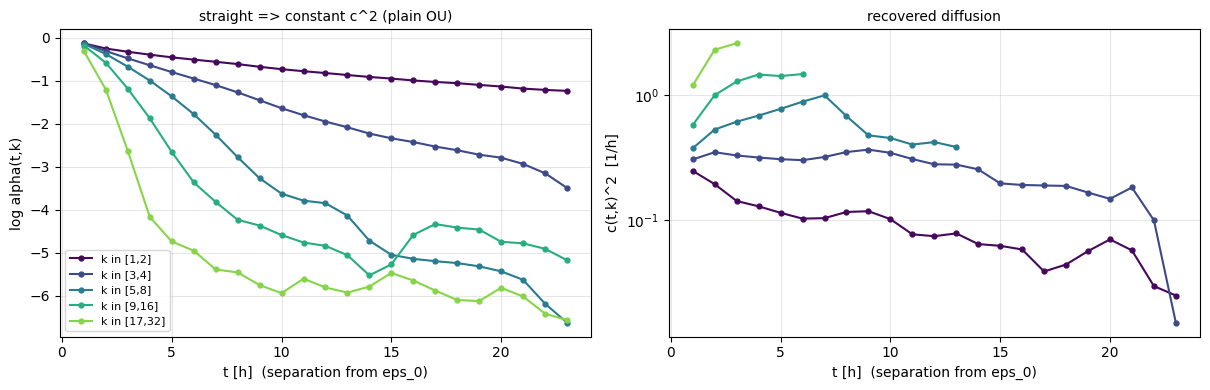

        band   c^2 t=1   c^2 t=4   c^2 t=12   (nan = alpha below floor)
  k in [1,2]     0.249     0.130      0.089
  k in [3,4]     0.308     0.319      0.281
  k in [5,8]     0.378     0.690      0.423
 k in [9,16]     0.581     1.470        nan
k in [17,32]     1.205       nan        nan


In [10]:
# --- recover the diffusion coefficient: c(t,k)^2 = -2 d/dt log alpha(t,k) ---
# A CONSTANT c^2 (plain OU) would make log alpha linear in t. Curvature = c is time-varying;
# a rising c^2 means the latent decorrelates faster later, falling means it stalls.
# Once alpha ~ 0 the latent has fully decorrelated and log alpha is pure noise, so its
# derivative is meaningless. Mask those cells rather than plotting noise as a diffusion.
import warnings
warnings.filterwarnings('ignore', message='Mean of empty slice')   # whole bands can be masked
ALPHA_FLOOR = 0.05
log_a = np.log(np.clip(alpha_hat, 1e-3, None))
c2    = -2 * np.gradient(log_a, leads.astype(float), axis=0)     # (L, B), units 1/h
c2    = np.where(alpha_hat > ALPHA_FLOOR, c2, np.nan)
print(f"c^2 reported only where alpha > {ALPHA_FLOOR} "
      f"({np.isfinite(c2[1:, 1:K_ISO+1]).mean():.0%} of (t,k) cells survive)")

# x axis is the SEPARATION t from eps_0, not the absolute lead tau.
# alpha[j] = corr(eps at index j, eps at index 0), so index j <-> t = j hours,
# while leads[j] = j+1 is the absolute lead. Plotting against leads[1:] would
# overstate t by one hour and disagree with the printed table.
seps = np.arange(1, L)                      # 1..23 h, matches alpha[1:]

fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.0))
for g in GROUPS:
    axes[0].plot(seps, log_a[1:, g[0]:g[1]+1].mean(1), 'o-', ms=3.5, lw=1.5,
                 color=gcol[g], label=f'k in [{g[0]},{g[1]}]')
    axes[1].plot(seps, np.nanmean(c2[1:, g[0]:g[1]+1], axis=1), 'o-', ms=3.5, lw=1.5, color=gcol[g])
axes[0].set_xlabel('t [h]  (separation from eps_0)'); axes[0].set_ylabel('log alpha(t,k)')
axes[0].set_title('straight => constant c^2 (plain OU)', fontsize=10)
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
axes[1].set_yscale('symlog', linthresh=0.1); axes[1].set_xlabel('t [h]  (separation from eps_0)')
axes[1].set_ylabel('c(t,k)^2  [1/h]'); axes[1].set_title('recovered diffusion', fontsize=10)
axes[1].grid(alpha=0.3)
fig.tight_layout(); plt.show()

print(f"{'band':>12}{'c^2 t=1':>10}{'c^2 t=4':>10}{'c^2 t=12':>11}   (nan = alpha below floor)")
for g in GROUPS:
    c1_, c4_, c12_ = (np.nanmean(c2[t, g[0]:g[1]+1]) for t in (1, 4, 12))
    print(f"{f'k in [{g[0]},{g[1]}]':>12}{c1_:>10.3f}{c4_:>10.3f}{c12_:>11.3f}")

## 6. Sample from the fitted process, forecast, evaluate

The flow model was trained on $z_0\sim\mathcal N(0,I)$, so the **marginal must stay white** — we impose only the *temporal* structure $\alpha(t,k)$ on white Fourier coefficients, we do not reproduce $\Sigma$.

Path form, not the closed form: stepping $a_k=\alpha(t_k)/\alpha(t_{k-1})$ gives $\mathrm{Cov}(\varepsilon_t,\varepsilon_s)=\alpha(t)/\alpha(s)$, the OU covariance. Drawing every lead from $\varepsilon_0$ in one shot would instead give $\alpha(t)\alpha(s)$, which is not OU.

⚠ **Costly — `RUN_FORECAST = False` by default.** Config below is the standard one.

100%|██████████| 5/5 [4:34:12<00:00, 3290.55s/it]  


[alpha_tk] 5 samples -> /home/trace/Documents/Projects/Thesis/data/predict_alpha_tk
Saved → /home/trace/Documents/Projects/Thesis/Visual/alpha_tk/sample00.gif
Saved → /home/trace/Documents/Projects/Thesis/Visual/alpha_tk/sample01.gif
Saved → /home/trace/Documents/Projects/Thesis/Visual/alpha_tk/sample02.gif


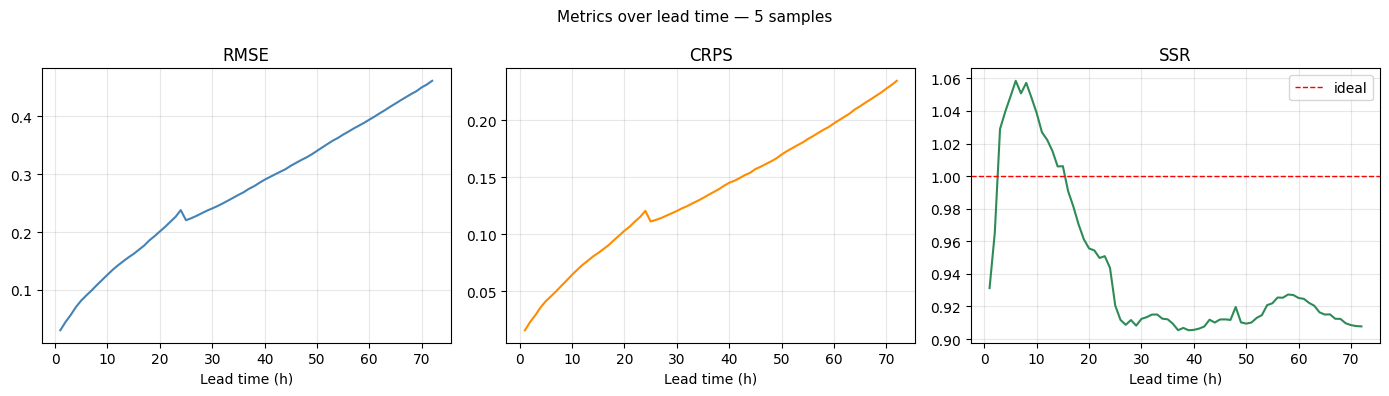

[alpha_tk] metrics plot -> Performance/metrics_alpha_tk.png
    t= 24 h   RMSE 0.2381   CRPS 0.1207   SSR 0.944
    t= 48 h   RMSE 0.3292   CRPS 0.1641   SSR 0.920
    t= 72 h   RMSE 0.4616   CRPS 0.2348   SSR 0.908


100%|██████████| 5/5 [4:30:19<00:00, 3243.81s/it]  


[alpha_0.5] 5 samples -> /home/trace/Documents/Projects/Thesis/data/predict_alpha_0.5
Saved → /home/trace/Documents/Projects/Thesis/Visual/alpha_0.5/sample00.gif
Saved → /home/trace/Documents/Projects/Thesis/Visual/alpha_0.5/sample01.gif
Saved → /home/trace/Documents/Projects/Thesis/Visual/alpha_0.5/sample02.gif


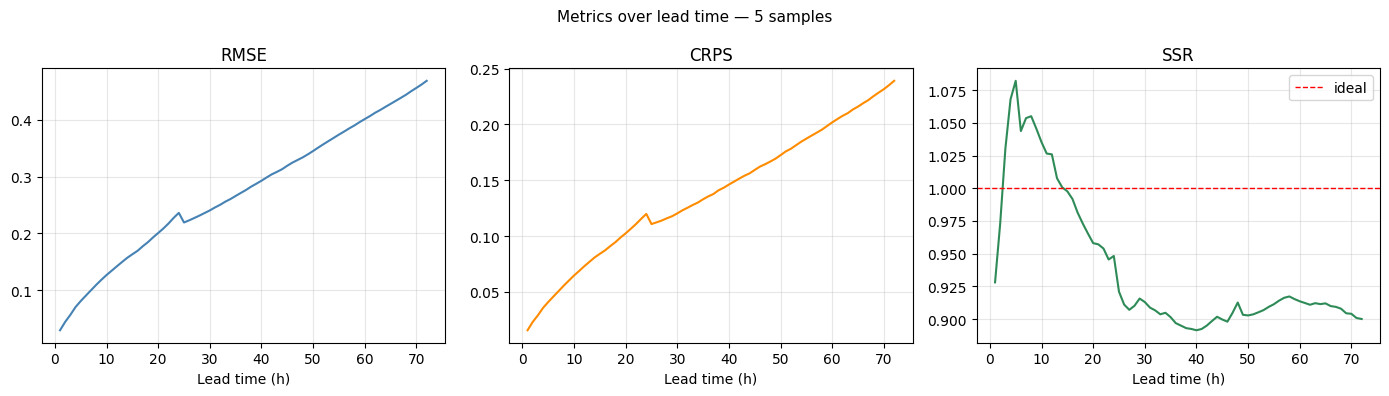

[alpha_0.5] metrics plot -> Performance/metrics_alpha_0.5.png
    t= 24 h   RMSE 0.2363   CRPS 0.1199   SSR 0.948
    t= 48 h   RMSE 0.3339   CRPS 0.1667   SSR 0.913
    t= 72 h   RMSE 0.4686   CRPS 0.2390   SSR 0.900


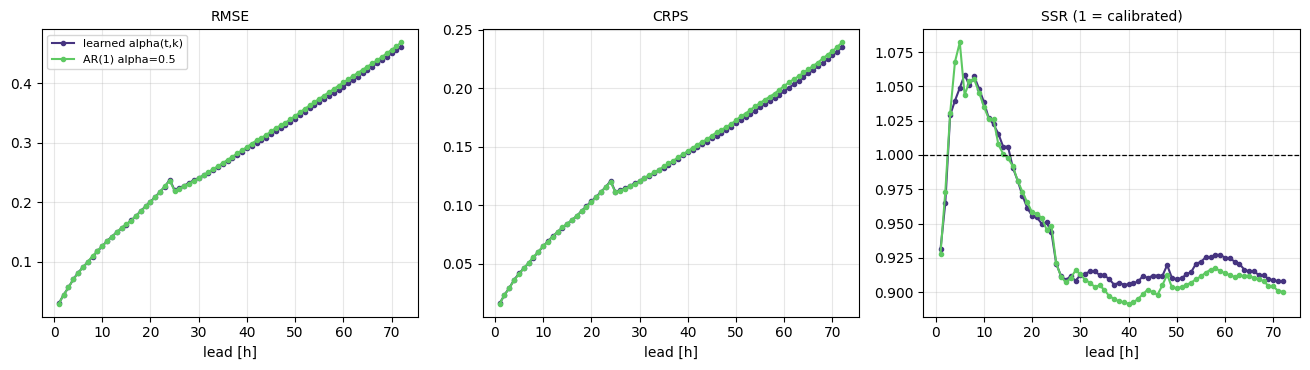

comparison -> Performance/metrics_alpha_tk_vs_0.5.png


In [5]:
def make_latent_fn(alpha_tk, seed=None):
    """Build the latent_fn that forecast() calls, from a fitted alpha(t,k).

    Generalises get_latents: that one is this with alpha(t,k) = sqrt(alpha) for every
    ring. Recipe per call: white noise field -> FFT -> per-ring AR step -> inverse FFT.

    Args:
        alpha_tk : (L, B) corr(eps_t, eps_0) per lead and ring, from fit_alpha. Row 0
                   must be 1 (it is, by construction).
        seed     : RNG seed, or None for fresh noise each call. Use None in a real
                   forecast — a fixed seed makes every ensemble member and every
                   autoregressive window reuse the SAME noise.

    Returns:
        latent_fn(shape, n_direct, dev) -> (n_direct * B_batch, C, H, W) float32 tensor
          shape    : (B_batch, C, H, W) as forecast() passes it, B_batch = ens * bs
          n_direct : number of direct leads, i.e. L
          dev      : device to place the result on
        Flattened batch-major / lead-minor to match get_latents, because time_labels is
        built in that order — get it wrong and every lead carries the wrong label.

    Guarantees: alpha is real and the FFT of a real field is Hermitian, so the inverse
    FFT is real; and a^2 + (1 - a^2) = 1 holds every lead at unit per-pixel variance,
    the marginal the flow model was trained on.
    """
    a_step = np.clip(alpha_tk[1:] / np.clip(alpha_tk[:-1], 1e-6, None), -1, 1)   # (L-1, B)

    def latent_fn(shape, n_direct, dev):
        Bn, Cn, Hn, Wn = shape
        g   = np.random.default_rng(seed).standard_normal((n_direct, Bn, Cn, Hn, Wn))
        gh  = np.fft.fft2(g, axes=(-2, -1))
        eh  = np.empty_like(gh)
        eh[0] = gh[0]                                        # eps_0 ~ N(0, I)
        for t in range(1, n_direct):
            a = a_step[t-1][kr]                              # (H, W) ring -> mode
            eh[t] = a * eh[t-1] + np.sqrt(np.clip(1 - a**2, 0, None)) * gh[t]
        z = np.fft.ifft2(eh, axes=(-2, -1)).real.astype(np.float32)
        # flatten EXACTLY as get_latents does: batch-major, lead-minor, to match time_labels
        z = torch.from_numpy(z).transpose(0, 1).reshape(n_direct * Bn, Cn, Hn, Wn)
        return z.to(dev)
    return latent_fn

torch.cuda.empty_cache()

# ---- standard configuration ------------------------------------------------
RUN_FORECAST = True         # <- flip on the server
CFG = dict(steps=1000,       # match the fidelity of data/invert_steps=1000
           eval_traj_num=5,
           ens=10,           # ens*L fields go through the UNet in ONE batch:
                             # 240 peaks at 3.45 GB here, 480 (ens=20) OOMs
           max_lead=L)
BASELINE_ALPHA = 0.5         # get_latents AR(1): rho(delta) = 0.5^(delta/2), one rate for every scale

ROOT   = DATA_PATH.parent    # absolute, so the output paths do not depend on the cwd
N_GIF  = 3                   # visualize_results writes ONE gif per sample; 100 is unusable

# Arms to run. tag also names every artefact the arm writes, so nothing collides with the
# existing data/predit_alpha=0.5 run or with Performance/metrics.png.
ARMS = [('alpha_tk',  dict(latent_fn=make_latent_fn(alpha_hat)), 'learned alpha(t,k)'),
        ('alpha_0.5', dict(alpha=BASELINE_ALPHA),                f'AR(1) alpha={BASELINE_ALPHA}')]

if RUN_FORECAST:
    smp  = CondSampler(model_path=SAVE_PATH, device=device, steps=CFG['steps'])
    runs = {}
    for tag, kw, name in ARMS:
        results = forecast(smp, eval_traj_num=CFG['eval_traj_num'], ens=CFG['ens'],
                           max_lead=CFG['max_lead'], device=device, **kw)
        runs[name] = results

        # 1. raw output — same layout perform_forecasting writes, so the saved runs are
        #    interchangeable with data/predit_alpha=0.5 (cell 11 loads that layout).
        pred_dir = DATA_PATH / f'predict_{tag}'
        pred_dir.mkdir(parents=True, exist_ok=True)
        for i, (p, t) in enumerate(results):
            np.save(pred_dir / f'sample{i:02d}_predicts.npy', p.numpy())
            np.save(pred_dir / f'sample{i:02d}_truth.npy',    t.numpy())
        print(f'[{tag}] {len(results)} samples -> {pred_dir}')

        # 2. gif animations, straight from utils. Truncated: one file per sample.
        visualize_results(results[:N_GIF], out_dir=str(ROOT / 'Visual' / tag))

        # 3. metrics, and the plot utils.plot_metrics saves for us
        m = compute_metrics(results)
        (ROOT / 'Performance').mkdir(parents=True, exist_ok=True)
        plot_metrics(m, out_path=str(ROOT / 'Performance' / f'metrics_{tag}.png'))
        print(f'[{tag}] metrics plot -> Performance/metrics_{tag}.png')
        for t in (24, 48, 72, 96):
            if t <= len(m['rmse']) and m['counts'][t-1] > 0:
                print(f"    t={t:>3} h   RMSE {m['rmse'][t-1]:.4f}   "
                      f"CRPS {m['crps'][t-1]:.4f}   SSR {m['ssr'][t-1]:.3f}")

    # the process that generated the alpha_tk run, so §6 can rerun without redoing §5
    np.save(DATA_PATH / 'latent_process_alpha_tk.npy', alpha_hat)

    # the comparison that matters: both arms on one axis
    fig, axes = plt.subplots(1, 3, figsize=(13.2, 3.8))
    for i, (name, res) in enumerate(runs.items()):
        m = compute_metrics(res)
        for ax, key, ttl in zip(axes, ['rmse', 'crps', 'ssr'], ['RMSE', 'CRPS', 'SSR (1 = calibrated)']):
            ax.plot(m['lead_times'], m[key], 'o-', ms=3, color=cmap(0.15 + 0.6*i), label=name)
            ax.set_xlabel('lead [h]'); ax.set_title(ttl, fontsize=10); ax.grid(alpha=0.3)
    axes[2].axhline(1.0, color='k', lw=0.9, ls='--'); axes[0].legend(fontsize=8)
    fig.savefig(ROOT / 'Performance' / 'metrics_alpha_tk_vs_0.5.png', dpi=150, bbox_inches='tight')
    fig.tight_layout(); plt.show()
    print('comparison -> Performance/metrics_alpha_tk_vs_0.5.png')
else:
    # cheap smoke test of the generator alone — no model calls, seconds not hours
    n_smoke = 64
    fn = make_latent_fn(alpha_hat, seed=0)
    z  = fn((n_smoke, C, H, W), L, 'cpu').reshape(n_smoke, L, C, H, W).numpy()
    zh = np.fft.fft2(z, axes=(-2, -1))

    # (i) marginal: each lead must be unit-variance white, NOT Sigma
    S_g  = ring_bin((np.abs(zh) ** 2).mean(axis=(0, 2))) / (H * W)       # (L, B)
    flat = S_g[:, 1:K_ISO+1] / S_g[:, 1:K_ISO+1].mean()
    # (ii) temporal: recover corr(eps_t, eps_0) PER RING and compare to the alpha it was built
    #      from. A pooled number would be mode-count weighted and dominated by high k.
    num  = ring_bin((zh * np.conj(zh[:, :1])).real.sum(2))               # (n, L, B)
    rho  = num.mean(0) / num.mean(0)[0][None, :]                         # (L, B)

    print("RUN_FORECAST = False — generator smoke test only")
    print(f"  per-lead std        {z.std(axis=(0,2,3,4)).min():.3f} .. {z.std(axis=(0,2,3,4)).max():.3f}"
          f"   (1.000 expected: marginal preserved)")
    print(f"  spectrum flatness   {flat.min():.2f} .. {flat.max():.2f}"
          f"   (1.00 expected: WHITE — the model was trained on N(0,I), so we do NOT reproduce Sigma)")
    print(f"\n  recovered vs target correlation, per ring band:")
    print(f"{'band':>12}" + "".join(f"{f't={t}':>16}" for t in [1, 4, 12]))
    for g in GROUPS:
        row = "".join(f"{rho[t, g[0]:g[1]+1].mean():>8.3f}/{alpha_hat[t, g[0]:g[1]+1].mean():<7.3f}"
                      for t in [1, 4, 12])
        print(f"{f'k in [{g[0]},{g[1]}]':>12}" + row)

## Where that leaves the model

Read the printed numbers against this:

- **§1–2** the latents pass per-pixel Gaussianity but fail spatial independence — $\Sigma\neq I$, red spectrum. And the rings move by *different* factors between leads, so $\Sigma_t$ is not one $\Sigma$ scaled by a scalar $\sigma(t)^2$: the shape changes with lead.
- **§2b** that is not an artifact of the integrator — 300-step and 1000-step inversions of the *same* windows recover the same latent to <0.3 %.
- **§3** the mapping bias does **not** accumulate. RMSE and CRPS against the observed fields are flat in lead, the floor is Euler discretisation ($\times10$ steps $\to\times\!\sim\!9$ less error), and it sits at small scales — $k\le2$ comes back near-exactly.
- **§4** the Fourier basis *is* the right one: off-diagonal coherence sits on its null at every lead, so rings are legitimate coordinates.
- **§5** whitening with $S_t(k)$, $\alpha(t,k)$ fits and **generalises** (no train/test gap on trajectory-grouped splits) and beats a scalar $\alpha(t)$ out of sample by up to $\times28$. That the ring-resolved fit does not degenerate to the scalar one is the same message as §2, arrived at from the estimation side. $c(t,k)^2$ is not constant — plain OU is an approximation.
- **§6** the sampler imposes $\alpha(t,k)$ on a white marginal, which is what the flow model was trained on.

Two open cracks, both worth naming:

1. $\alpha$ and $c^2$ are fitted under a marginal that §2 says is moving. §6's generator holds the marginal white by construction, so it is self-consistent — but the data it was fitted to is not.
2. Channels are **pooled** throughout: every ring quantity sums over the two SQG levels, so $\Sigma$'s $2\times2$ channel block is never resolved and `dof_b = ring_n * C` assumes the levels are independent. §1 shows a small, consistently positive cross-channel correlation (~0.03), which is untested here. Out of scope by choice, not because it is zero.

## 7. Temporal difference — is the forecast continuous?

$$\Delta X := \frac{1}{N}\sum_{n=1}^{N}\frac{1}{n_{\rm ens}}\sum_{k=1}^{n_{\rm ens}}\frac{1}{|I|}\sum_{i \in I} a_i\,\big|x^k_{i,n} - \hat x^k_{i,n}\big|$$

$x$ and $\hat x$ are the **same** forecast at consecutive lead times, so this measures step-to-step continuity, not accuracy. The truth curve is the reference: below it the forecast is too smooth, above it too jumpy.

truth                      dX  t=1->2 0.1532   t=23->24 0.1469   mean 0.1500   (n=5)
baseline  AR(1) alpha=0.5  dX  t=1->2 0.1503   t=23->24 0.1596   mean 0.1527   (n=5)
proposal  alpha(t,k)       dX  t=1->2 0.1513   t=23->24 0.2711   mean 0.1928   (n=5)


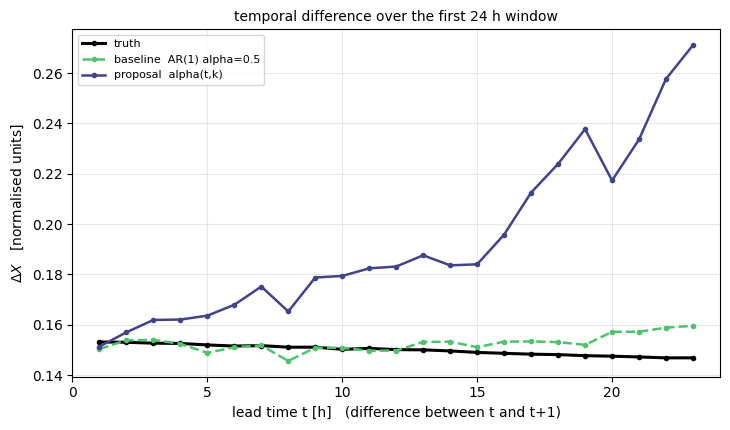

In [7]:
# Temporal difference, eq. (6), restricted to the FIRST 24 h window.
#
# Why only window 0: past lead 24 the AR loop re-anchors on its own forecast, which is
# not what the model was trained on, and both arms degrade the same way. Window 0 is
# anchored on the TRUE state throughout, so it is the only in-distribution comparison.
# It also means every sample contributes at every lead (no ragged averaging) and no
# difference straddles a re-anchoring boundary.
#
# NOTE this metric compares a forecast against ITSELF one lead later — nothing is scored
# against the truth. Truth gets its own curve as the reference a continuous forecast
# should sit at: below it is too smooth, above it too jumpy.
#
# a_i are area weights. This is a doubly-periodic Cartesian 64x64 grid, so every cell has
# equal area and (1/|I|) * sum_i a_i |.| is a plain spatial mean; the hook is kept for a
# lat-weighted grid where it would not be.

def temporal_difference(arr, area_w=None):
    """Mean absolute change between consecutive lead times.

    Args:
        arr    : (T, ens, C, H, W) forecast, or (T, C, H, W) truth (treated as 1 member)
        area_w : (H, W) area weights a_i, or None for the uniform grid here

    Returns:
        (T-1,) — entry j is the mean |x_{j+1} - x_j| over members, channels and cells.
    """
    if arr.ndim == 4:
        arr = arr[:, None]                                  # truth -> a single member
    d = np.abs(np.diff(arr, axis=0))                        # (T-1, ens, C, H, W)
    if area_w is None:
        return d.mean(axis=(1, 2, 3, 4))
    return (d * area_w).sum(axis=(3, 4)).mean(axis=(1, 2)) / area_w.sum()

def dx_curve(paths):
    """Mean dX over samples, using AR window 0 only.

    np.load(p)[0] takes the first AR window: (n_ar, n_lead, ...) -> (n_lead, ...).
    Every sample has one, so the curves are all length n_lead-1 and average directly.

    Returns:
        (dx, n) : dx (n_lead-1,) mean curve over the n samples.
    """
    curves = np.stack([temporal_difference(np.load(p)[0]) for p in paths])
    return curves.mean(0), len(curves)

BASE_DIR, PROP_DIR = DATA_PATH / 'predict_alpha_0.5', DATA_PATH / 'predict_alpha_tk'
names = sorted(f.name for f in PROP_DIR.glob('*_predicts.npy'))
assert names == sorted(f.name for f in BASE_DIR.glob('*_predicts.npy')), 'arms do not pair by filename'

# the two arms forecast the SAME anchors, so their truth files must be identical
t_names = [n.replace('_predicts', '_truth') for n in names]
assert all(np.array_equal(np.load(BASE_DIR / t), np.load(PROP_DIR / t)) for t in t_names), \
    'truth differs between arms — they did not forecast the same anchors'

series = [('truth',                     [BASE_DIR / t for t in t_names], 'k',        2.2, '-'),
          ('baseline  AR(1) alpha=0.5', [BASE_DIR / n for n in names],   cmap(0.72), 1.8, '--'),
          ('proposal  alpha(t,k)',      [PROP_DIR / n for n in names],   cmap(0.20), 1.8, '-')]

fig, ax = plt.subplots(figsize=(7.4, 4.4))
for label, paths, col, lw, ls in series:
    dx, n = dx_curve(paths)
    ax.plot(np.arange(1, len(dx) + 1), dx, ls, lw=lw, color=col, marker='o', ms=3, label=label)
    print(f"{label:<26} dX  t=1->2 {dx[0]:.4f}   t=23->24 {dx[-1]:.4f}   mean {dx.mean():.4f}   (n={n})")
ax.set_xlim(0, 24)
ax.set_xlabel('lead time t [h]   (difference between t and t+1)')
ax.set_ylabel(r'$\Delta X$   [normalised units]')
ax.set_title('temporal difference over the first 24 h window', fontsize=10)
ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()